# Wykład 13, cz. 1: techniki analizy danych i płytkiego uczenia maszynowego

### Dwa podstawowe problemy w uczeniu maszynowym:
1. Klasyfikacja: przypisanie danym etykietek.
2. Regresja: przewidywanie wartości ciągłej cechy na podstawie pozostałych cech.

Na poprzednim wykładzie użyliśmy regresji liniowej, aby zastąpić wartości cechy prostym wyrażeniem (od pozostałych cech). Teraz w podobny sposób chcemy znaleźć (możliwie prostą) regułę, opisującą cechę kategoryczną.

Użyjemy znanego zestawu win: jak w łatwy sposób odgadnąć klasę wina na podstawie zawartości alkoholu, kwasu jabłkowego, etc.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("wine.txt")

In [3]:
df.head() # domyślnie 5 rekordów

,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


Poza `class`, każdy gatunek wina ma 13 cech. Wszystkie cechy te cechy są ciągłe (składają się z liczb rzeczywistych).

## Przykład 1 - klasyfikacja przez centroidy

Dla każdej klasy gatunku wina wyliczamy "średni" gatunek wina. Dla wina o nieznanej klasie wyznaczamy ją poprzez wzięcie klasy najbliższego uśrednionego wina.

Formalnie: dla danych $\mathbf{x}_0, \mathbf{x}_1, \ldots, \mathbf{x}_{n-1} \in \mathbb{R}^d$ oraz etykietek $y_0, y_1, \ldots, y_{n-1} \in \{0, \ldots, N - 1\}$ definiujemy $N$ *centroidów* $C_0, C_1, \ldots, C_{N-1}$:

$$
C_k := \frac{1}{|\{i : y_i = k\}|}\sum_{y_i = k} \mathbf{x}_{i}.
$$

Następnie dla punktu $\mathbf{x} \in \mathbb{R}^d$ modelujemy jego etykietę poprzez

$$
\hat{y} := \underset{i}{\mathrm{argmin}} ~ ||\mathbf{x} - C_i||,
$$
gdzie $\underset{i}{\mathrm{argmin}} ~ a_i$ oznacza $i$ takie, że $a_i$ jest najmniejsze możliwe.

Wyznaczmy centroidy:

In [4]:
mean_wine = df.groupby("class").mean()
mean_wine

,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
class,,,,,,,,,,,,,
1,13.744746,2.010678,2.455593,17.037288,106.338983,2.840169,2.982373,0.290000,1.899322,5.528305,1.062034,3.157797,1115.711864
2,12.278732,1.932676,2.244789,20.238028,94.549296,2.258873,2.080845,0.363662,1.630282,3.086620,1.056282,2.785352,519.507042
3,13.153750,3.333750,2.437083,21.416667,99.312500,1.678750,0.781458,0.447500,1.153542,7.396250,0.682708,1.683542,629.895833


Zamiast brać wszystkie 13 cech, wybierzmy na początku dwie `Alcohol` i `Malic acid`. Wtedy mamy do czynienia z danymi dwuwymiarowymi.

In [5]:
centroids = mean_wine[["Alcohol", "Malic acid"]].to_numpy()

In [6]:
X = df[["Alcohol", "Malic acid"]].to_numpy()
y = df["class"].to_numpy().astype(int)

In [7]:
color_map = np.array(["red", "green", "blue"])

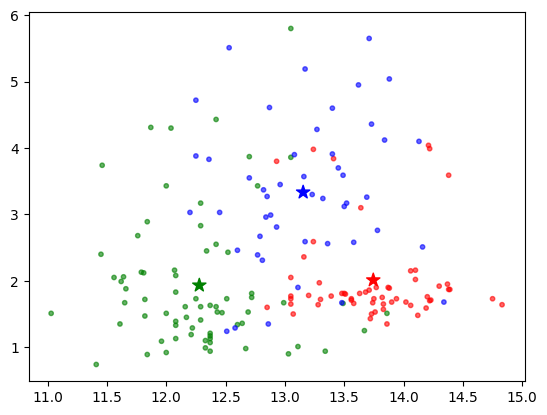

In [8]:
plt.scatter(X[:,0], X[:,1], c=color_map[y - 1], alpha=0.6, s=10)
plt.scatter(centroids[:,0], centroids[:,1], c=color_map, marker="*", s=100)
plt.show()

Dla punktu $\mathbf{x} \in \mathbb{R}^2$:

In [9]:
x = np.array([12.5, 2.5])

Kwadraty odległości od centroidów:

In [10]:
np.sum((x - centroids)**2, axis=1)

array([1.78882807, 0.37081581, 1.12252813])

Najbliższy centroid:

In [11]:
y_pred = np.argmin(np.sum((x - centroids)**2, axis=1))
y_pred

1

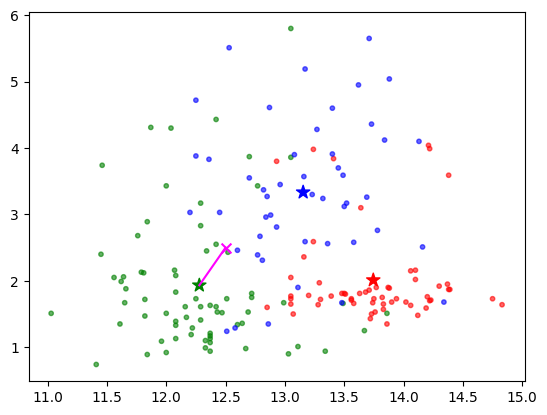

In [12]:
plt.scatter(X[:,0], X[:,1], c=color_map[y - 1], alpha=0.6, s=10)
plt.scatter(centroids[:,0], centroids[:,1], c=color_map, marker="*", s=100)
plt.scatter(*x, c="magenta", marker="x", s=50)

plt.plot([x[0], centroids[y_pred, 0]], [x[1], centroids[y_pred,1]], color="magenta")

plt.show()

A dla wielu punktów:

In [13]:
X2 = np.array([[12.5, 2.5], [14, 1.5]])

In [14]:
dist2 = np.sum((X2[:, None, :] - centroids[None, :, :])**2, axis=2) # dodanie wymiarów + broadcasting

In [15]:
dist2

array([[1.78882807, 0.37081581, 1.12252813],
       [0.32594671, 3.14997074, 4.07877813]])

In [16]:
y_pred = np.argmin(dist2, axis=1)
y_pred

array([1, 0], dtype=int64)

To samo jako klasa $\to$ PyCharm.

In [17]:
from wyklad13_centroids import CentroidClassifier0

In [18]:
clf = CentroidClassifier0()
clf.fit0(centroids)

Ta procedura zadaje podział płaszczyzny - zaznaczmy jej kontur:

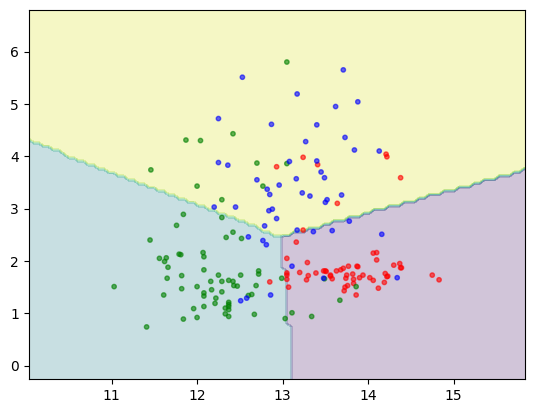

In [19]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

XX = np.c_[xx.ravel(), yy.ravel()]
zz = clf.predict0(XX)

plt.contourf(xx, yy, zz.reshape(xx.shape), alpha=0.25)

plt.scatter(X[:,0], X[:,1], c=color_map[y - 1], alpha=0.6, s=10)

plt.show()

Ten podział to diagram Woronoja, gdzie centroidy to ogniska.

Jak skuteczny jest podział? Policzmy ułamek dobrze odtworzonych etykiet.

In [20]:
y_pred = clf.predict0(X) + 1 # etykietki 0,1,2 -> 1,2,3

In [21]:
np.mean(y_pred == y)

0.7921348314606742

Około 80%. A gdyby wykorzystać inne dwie cechy?

In [22]:
X = df[["Flavanoids", "Color intensity"]].to_numpy()
centroids = mean_wine[["Flavanoids", "Color intensity"]].to_numpy()

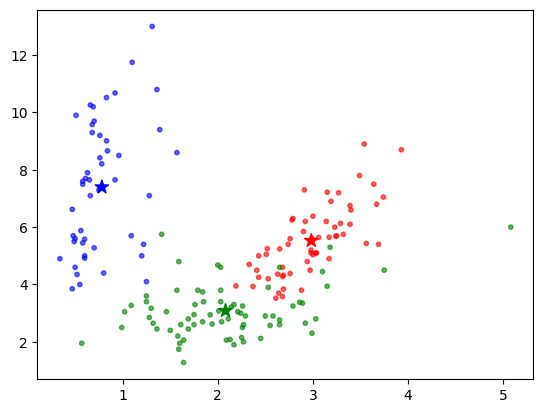

In [23]:
plt.scatter(X[:,0], X[:,1], c=color_map[y - 1], alpha=0.6, s=10)
plt.scatter(centroids[:,0], centroids[:,1], c=color_map, marker="*", s=100)
plt.show()

In [24]:
clf.fit0(centroids)
y_pred = clf.predict0(X)

In [25]:
np.mean(y_pred + 1== y)

0.8370786516853933

Marginalnie lepiej. A dla wszystkich kolumn?

In [26]:
centroids = mean_wine.to_numpy()

In [27]:
centroids.shape

(3, 13)

In [28]:
X = df.drop(columns="class").to_numpy()
X.shape

(178, 13)

In [29]:
clf.fit0(centroids)

In [30]:
y_pred = clf.predict0(X)

In [31]:
np.mean(y_pred + 1== y)

0.7247191011235955

Gorzej. Dlaczego? Wrócimy do tego problemu.

## Przykład 2 - klasyfikacja przez $k$ najbliższe sąsiednie punkty

$k$-nearest neighbors, kNN - klasyfikacja przez "głosowanie".

$k$ - ustalona liczba naturalna.

Dla punktu $\mathbf{x}$, jego klasa jest przyznawana następująco:
- Znajdujemy $k$ znanych punktów $p_1, p_2, \ldots, p_k$, położonych najbliżej $\mathbf{x}$ (zazwyczaj w odległości euklidesowej).
- Przyznajemy $\mathbf{x}$ etykietę, która wystąpiła najczęściej wśród etykietek $p_1, \ldots, p_k$.
- (są różne strategie postępowania w przypadku remisów)

Przykład dla win i $k=5$:

In [32]:
X = df[["Alcohol", "Malic acid"]].to_numpy()
y = df["class"].to_numpy().astype(int)

In [33]:
k = 5
p = np.array([12.5, 5])

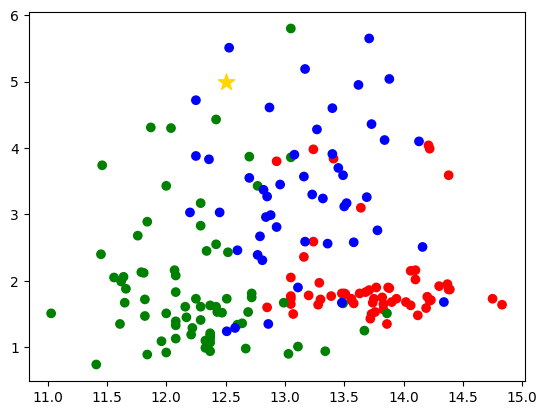

In [34]:
plt.scatter(X[:,0], X[:,1], c=color_map[y - 1])
plt.scatter(p[0], p[1], marker='*', c='gold', s=150)
plt.show()

Wyznaczamy $k=5$ najbliższych punktów:

In [35]:
dist_sq = np.sum((X - p)**2, axis=1)
closest_idx = np.argpartition(dist_sq, k)[:k]
closest = X[closest_idx]
print(closest)

[[12.25  4.72]
 [12.53  5.51]
 [12.87  4.61]
 [12.42  4.43]
 [13.17  5.19]]


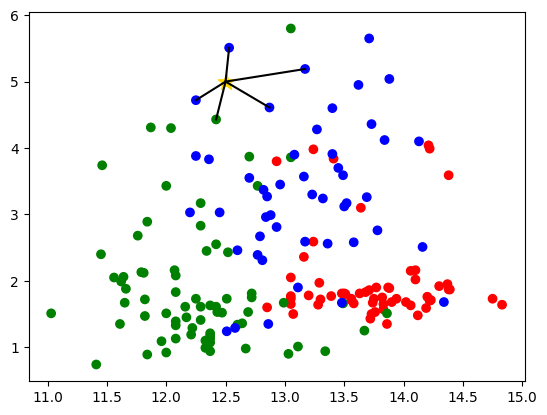

In [36]:
plt.scatter(X[:,0], X[:,1], c=color_map[y - 1])
plt.scatter(p[0], p[1], marker='*', c='gold', s=150)

for px, py in closest:
    plt.plot([p[0], px], [p[1], py], color='black')

plt.show()

Wyznaczone klasy najbliższych punktów:

In [37]:
y[closest_idx]

array([3, 3, 3, 2, 3])

Najczęstszy wynik:

In [38]:
values, counts = np.unique(y[closest_idx], return_counts=True)
values[np.argmax(counts)]

3

Jako klasa $\to$ PyCharm.

In [39]:
from wyklad13_knn import KNNClassifier

In [40]:
clf = KNNClassifier(k=5)

In [41]:
clf.fit(X, y)

In [42]:
y_pred = clf.predict(X)

In [43]:
np.mean(y_pred == y)

0.8651685393258427

Dla wszystkich kolumn:

In [44]:
X = df.drop(columns="class").to_numpy()

In [45]:
clf.fit(X, y)
y_pred = clf.predict(X)
np.mean(y_pred == y)

0.7865168539325843

In [46]:
print("\U0001f620")

😠


Problem - dane są w różnych jednostkach, znacznie różnią się zakresami.

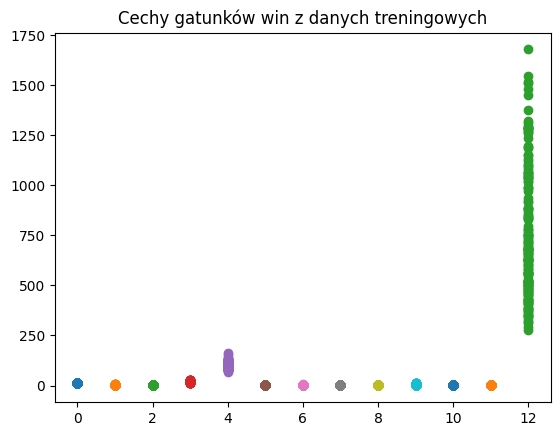

In [47]:
h, _ = X.shape
for i in range(13):
    plt.scatter([i] * h, X[:,i])
plt.title("Cechy gatunków win z danych treningowych")
plt.show()

Odległości między punktami są zdominowane przez odległości na ostatniej współrzędnej!

Rozwiązanie - normalizacja danych.

Dwie cechy statystyczne dla danych $x_0, x_1, \ldots, x_{n-1} \in \mathbb{R}$:
- Średnia:
$$\mu = \bar x = \frac{1}{n} \sum_{i<n} x_i$$.
- Odchylenie standardowe (populacji):
$$\sigma = \sqrt{\frac{1}{n}\sum_{i<n}(x_i - \mu)^2}.$$

Odchylenie standardowe mierzy "rozrzut" wartości w danych. Kwadratem odchylenia standardowego jest *wariancja*.

In [48]:
a = np.array([1, 2, 3, 4, 5])
mu = np.mean(a)
np.mean((a - mu)**2)**0.5 # == 2**0.5

1.4142135623730951

In [49]:
np.std([1, 2, 3, 4, 5])

1.4142135623730951

In [50]:
np.std(np.random.uniform(0, 1, 10000))

0.2870506785267534

In [51]:
np.std(np.random.normal(0, 1, 10000))

0.998027195240809

Normalizacja danych (ciągu punktów w $\mathbb{R}$) - zastąpienie danych przez nałożenie na nich funkcji $f(x) = \frac{x - \mu}{\sigma}$.

Dla zestawu danych (cechy zebrane w kolumny), normalizacja polega na normalizacji każdej kolumny z osobna.

Taka normalizacja to wyrażenie starych danych w nowych, "wewnętrznych" jednostkach, mających porównywalny rozrzut wartości.
Dane są też *wycentrowane* - ich nowa średnia to $0$ (w każdej kolumnie).

In [52]:
means = X.mean(axis=0)
means

array([1.30006180e+01, 2.33634831e+00, 2.36651685e+00, 1.94949438e+01,
       9.97415730e+01, 2.29511236e+00, 2.02926966e+00, 3.61853933e-01,
       1.59089888e+00, 5.05808988e+00, 9.57449438e-01, 2.61168539e+00,
       7.46893258e+02])

In [53]:
stds = X.std(axis=0)
stds

array([8.09542915e-01, 1.11400363e+00, 2.73572294e-01, 3.33016976e+00,
       1.42423077e+01, 6.24090564e-01, 9.96048950e-01, 1.24103260e-01,
       5.70748849e-01, 2.31176466e+00, 2.27928607e-01, 7.07993265e-01,
       3.14021657e+02])

In [54]:
X_scaled = (X - means) / stds

In [55]:
X_scaled.mean(axis=0)

array([-8.38280756e-16, -1.19754394e-16, -8.37033314e-16, -3.99181312e-17,
       -3.99181312e-17,  0.00000000e+00, -3.99181312e-16,  3.59263181e-16,
       -1.19754394e-16,  2.49488320e-17,  1.99590656e-16,  3.19345050e-16,
       -1.59672525e-16])

In [56]:
X_scaled.std(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

Teraz powtórzymy eksperyment klasyfikacyjny z KNN:

In [57]:
clf = KNNClassifier(k=5)

In [58]:
clf.fit(X_scaled, y)
y_pred = clf.predict(X_scaled)
np.mean(y_pred == y)

0.9775280898876404

In [59]:
print("\U0001f600*")

😀*


Skalowanie opakowane w klasę $\to$ PyCharm.

In [60]:
from wyklad13_standardscaler import StandardScaler

In [61]:
clf = KNNClassifier(k=5)
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

clf.fit(X_scaled, y)
y_pred = clf.predict(X_scaled)
np.mean(y_pred == y)

0.9775280898876404

## Walidacja modeli

Jaką wartość mają powyższe testy? Niekoniecznie dużą, bo weryfikujemy model na podstawie danych, które zostały przekazane przy "treningu":

In [62]:
clf = KNNClassifier(k=1)
clf.fit(X, y)
y_pred = clf.predict(X)
np.mean(y_pred == y)

1.0

Ten model się nie myli, ale czy dobrze się uogólnia (czy dobrze przewiduje etykiety dla nowych, nieznanych danych)? Nie wiadomo, bo jeszcze ich nie mamy.

Pomysł: wydzielić część dostępnych nam danych jako *dane testowe*. Pozostałe dane to *dane treningowe*. Budujemy model w oparciu o dane treningowe (udając, że to jedyne, jakie mamy), a testujemy w oparciu o dane testowe (udając, że są to dane, które napotkamy w przyszłości).

Reszta wykładu $\to$ PyCharm